# Recommendation System Project: IBM Community

In this notebook we put recommendation techniques to work on real data from the IBM Watson Studio platform: which users interacted with which articles. The notebook builds four recommenders and compares them:

* **Rank-based** (popularity) - for brand-new users
* **User-user collaborative filtering** - for users with some history
* **Content-based** (TF-IDF + KMeans on article titles) - for "more like this" suggestions
* **Matrix factorization** (SVD) - latent-feature similarity between articles

The same logic is also packaged as a reusable class in [`ibm_recommender/`](../ibm_recommender) (see the repository README) so it can be used from a web app.

## Table of Contents

I. [Exploratory Data Analysis](#Exploratory-Data-Analysis)<br>
II. [Rank Based Recommendations](#Rank)<br>
III. [User-User Based Collaborative Filtering](#User-User)<br>
IV. [Content Based Recommendations](#Content-Recs)<br>
V. [Matrix Factorization](#Matrix-Fact)<br>
VI. [Extras & Concluding](#conclusions)

Let's start by importing the necessary libraries and reading in the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import project_tests as t


df = pd.read_csv(
    'data/user-item-interactions.csv', 
    dtype={'article_id': int, 'title': str, 'email': str}
)
# Show df to get an idea of the data
df.head()

,Unnamed: 0,article_id,title,email
0,0,1430,"using pixiedust for fast, flexible, and easier...",ef5f11f77ba020cd36e1105a00ab868bbdbf7fe7
1,1,1314,healthcare python streaming application demo,083cbdfa93c8444beaa4c5f5e0f5f9198e4f9e0b
2,2,1429,use deep learning for image classification,b96a4f2e92d8572034b1e9b28f9ac673765cd074
3,3,1338,ml optimization using cognitive assistant,06485706b34a5c9bf2a0ecdac41daf7e7654ceb7
4,4,1276,deploy your python model as a restful api,f01220c46fc92c6e6b161b1849de11faacd7ccb2


### <a class="anchor" id="Exploratory-Data-Analysis">Part I : Exploratory Data Analysis</a>

Use the dictionary and cells below to provide some insight into the descriptive statistics of the data.

`1.` Are there any missing values? If so, provide a count of missing values. If there are missing values in `email`, assign it the same id value `"unknown_user"`.

In [2]:
# Some interactions do not have a user associated with it, assume the same user.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45993 entries, 0 to 45992
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  45993 non-null  int64
 1   article_id  45993 non-null  int64
 2   title       45993 non-null  str  
 3   email       45976 non-null  str  
dtypes: int64(2), str(2)
memory usage: 1.4 MB


In [3]:
n_null_email = df['email'].isna().sum()
print(f"Number of Null email values is: {n_null_email}")
print(df.isna().sum())

Number of Null email values is: 17
Unnamed: 0     0
article_id     0
title          0
email         17
dtype: int64


In [4]:
df[df.email.isna()]

,Unnamed: 0,article_id,title,email
25131,25146,1016,why you should master r (even if it might even...,NaN
29758,30157,1393,the nurse assignment problem,NaN
29759,30158,20,working interactively with rstudio and noteboo...,NaN
29760,30159,1174,breast cancer wisconsin (diagnostic) data set,NaN
29761,30160,62,data visualization: the importance of excludin...,NaN
35264,36016,224,"using apply, sapply, lapply in r",NaN
35276,36029,961,beyond parallelize and collect,NaN
35277,36030,268,sector correlations shiny app,NaN
35278,36031,268,sector correlations shiny app,NaN
35279,36032,268,sector correlations shiny app,NaN


In [5]:
# Fill email NaNs with "unknown_user" (all anonymous interactions are treated as one user)
df['email'] = df['email'].fillna('unknown_user')

In [6]:
# Check if no more NaNs 
df[df.email.isna()]

,Unnamed: 0,article_id,title,email


`2.` What is the distribution of how many articles a user interacts with in the dataset?  Provide a visual and descriptive statistics to assist with giving a look at the number of times each user interacts with an article.

In [7]:
# Interactions per user (each row of df is one user-article interaction)
user_counts = df.groupby('email').size()
user_counts.describe()

count    5149.000000
mean        8.932414
std        16.801011
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       364.000000
dtype: float64

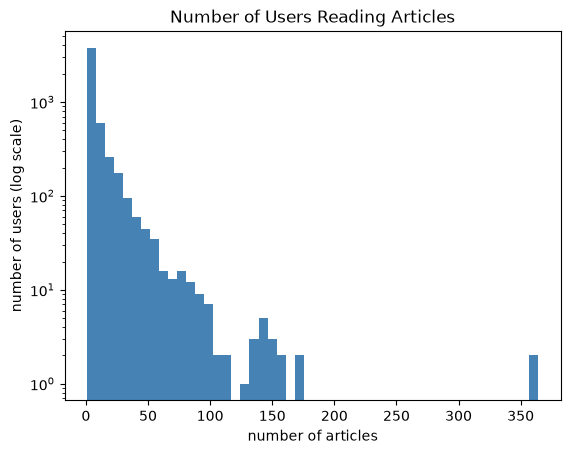

In [8]:
# Create a plot of the number of articles read by each user
plt.hist(user_counts, bins=50, color='steelblue')
plt.yscale('log')  # heavily right-skewed: most users read very few articles
plt.xlabel('number of articles')
plt.ylabel('number of users (log scale)')
plt.title('Number of Users Reading Articles')
plt.show()

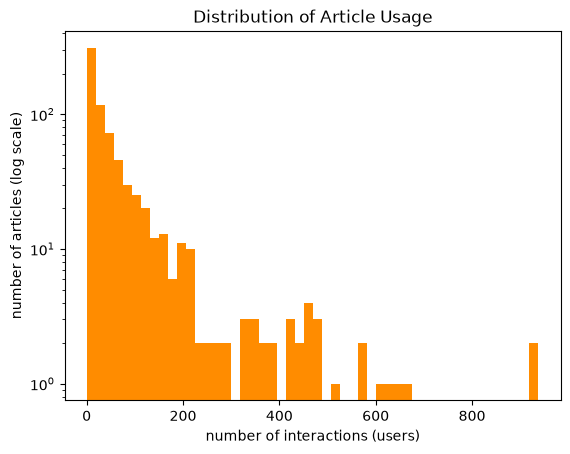

In [9]:
# Create a plot of the number of times each article was read
article_counts = df.groupby('article_id').size()
plt.hist(article_counts, bins=50, color='darkorange')
plt.yscale('log')
plt.xlabel('number of interactions (users)')
plt.ylabel('number of articles (log scale)')
plt.title('Distribution of Article Usage')
plt.show()

In [10]:
# Fill in the median and maximum number of user_article interactions below
median_val = int(user_counts.median())  # 50% of individuals interact with ____ number of articles or fewer.
max_views_by_user = int(user_counts.max())  # The maximum number of user-article interactions by any 1 user is ______.

`3.` Use the cells below to find:

**a.** The number of unique articles that have an interaction with a user.  
**b.** The number of unique articles in the dataset (whether they have any interactions or not).<br>
**c.** The number of unique users in the dataset. (excluding null values) <br>
**d.** The number of user-article interactions in the dataset.

In [11]:
unique_articles = int(df['article_id'].nunique())  # The number of unique articles that have at least one interaction
# Only the interactions file exists in this project version, so every known article has >= 1 interaction
total_articles = int(df['article_id'].nunique())  # The number of unique articles on the IBM platform
# After filling nulls, the anonymous "unknown_user" counts as one user (5148 real users + 1)
unique_users = int(df['email'].nunique())  # The number of unique users
user_article_interactions = int(len(df))  # The number of user-article interactions

`4.` Use the cells below to find the most viewed **article_id**, as well as how often it was viewed.  After talking to the company leaders, the `email_mapper` function was deemed a reasonable way to map users to ids.  There were a small number of null values, and it was found that all of these null values likely belonged to a single user (which is how they are stored using the function below).

In [12]:
most_viewed_article_id = int(article_counts.idxmax())  # The most viewed article in the dataset (id as int, as the test expects)
max_views = int(article_counts.max())  # The most viewed article in the dataset was viewed how many times?

In [13]:
## No need to change the code here - this will be helpful for later parts of the notebook
# Run this cell to map the user email to a user_id column and remove the email column

def email_mapper(df=df):
    """
    INPUT:
    df - (pandas dataframe) interactions with an `email` column (nulls already filled)

    OUTPUT:
    user_ids - (list) one integer id per row, numbered from 1 in order of first appearance of each email
    """
    coded_dict = {
        email: num 
        for num, email in enumerate(df['email'].unique(), start=1)
    }
    return [coded_dict[val] for val in df['email']]

df['user_id'] = email_mapper(df)
del df['email']

# show header
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [14]:
## If you stored all your results in the variable names above, 
## you shouldn't need to change anything in this cell

sol_1_dict = {
    '`50% of individuals have _____ or fewer interactions.`': median_val,
    '`The total number of user-article interactions in the dataset is ______.`': user_article_interactions,
    '`The maximum number of user-article interactions by any 1 user is ______.`': max_views_by_user,
    '`The most viewed article in the dataset was viewed _____ times.`': max_views,
    '`The article_id of the most viewed article is ______.`': most_viewed_article_id,
    '`The number of unique articles that have at least 1 rating ______.`': unique_articles,
    '`The number of unique users in the dataset is ______`': unique_users,
    '`The number of unique articles on the IBM platform`': total_articles
}

# Test your dictionary against the solution
t.sol_1_test(sol_1_dict)

It looks like you have everything right here! Nice job!


### <a class="anchor" id="Rank">Part II: Rank-Based Recommendations</a>

In this project, we don't actually have ratings for whether a user liked an article or not.  We only know that a user has interacted with an article. In these cases, the popularity of an article can really only be based on how often an article was interacted with.

`1.` Fill in the function below to return the **n** top articles ordered with most interactions as the top. Test your function using the tests below.

In [15]:
def get_article_names(article_ids, df=df):
    """
    INPUT:
    article_ids - (list) a list of article ids
    df - (pandas dataframe) df as defined at the top of the notebook

    OUTPUT:
    article_names - (list) a list of article names associated with the list of article ids
                    (this is identified by the title column in df)
    """
    id_to_title = df.drop_duplicates('article_id').set_index('article_id')['title']
    return id_to_title.loc[list(article_ids)].tolist()


def get_top_article_ids(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook

    OUTPUT:
    top_articles - (list) A list of the top 'n' article ids, most interactions first
    """
    return df['article_id'].value_counts().head(n).index.tolist()


def get_top_articles(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook

    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles, most interactions first
    """
    return get_article_names(get_top_article_ids(n, df), df)

In [16]:
print(get_top_articles(10))
print(get_top_article_ids(10))

['use deep learning for image classification', 'insights from new york car accident reports', 'visualize car data with brunel', 'use xgboost, scikit-learn & ibm watson machine learning apis', 'predicting churn with the spss random tree algorithm', 'healthcare python streaming application demo', 'finding optimal locations of new store using decision optimization', 'apache spark lab, part 1: basic concepts', 'analyze energy consumption in buildings', 'gosales transactions for logistic regression model']
[1429, 1330, 1431, 1427, 1364, 1314, 1293, 1170, 1162, 1304]


In [17]:
# Test your function by returning the top 5, 10, and 20 articles
top_5 = get_top_articles(5)
top_10 = get_top_articles(10)
top_20 = get_top_articles(20)

# Test each of your three lists from above
t.sol_2_test(get_top_articles)

Your top_5 looks like the solution list! Nice job.
Your top_10 looks like the solution list! Nice job.
Your top_20 looks like the solution list! Nice job.


### <a class="anchor" id="User-User">Part III: User-User Based Collaborative Filtering</a>


`1.` Use the function below to reformat the **df** dataframe to be shaped with users as the rows and articles as the columns.  

* Each **user** should only appear in each **row** once.


* Each **article** should only show up in one **column**.  


* **If a user has interacted with an article, then place a 1 where the user-row meets for that article-column**.  It does not matter how many times a user has interacted with the article, all entries where a user has interacted with an article should be a 1.  


* **If a user has not interacted with an item, then place a zero where the user-row meets for that article-column**. 

Use the tests to make sure the basic structure of your matrix matches what is expected by the solution.

In [18]:
def create_user_item_matrix(df, fill_value=0):
    """
    INPUT:
    df - pandas dataframe with article_id, title, user_id columns
    fill_value - value used where a user never interacted with an article

    OUTPUT:
    user_item - user item matrix

    Description:
    Return a matrix with user ids as rows and article ids on the columns with 1 values where a user interacted with
    an article and a 0 otherwise
    """
    pairs = df[['user_id', 'article_id']].drop_duplicates().assign(interacted=1)
    user_item = pairs.pivot(index='user_id', columns='article_id', values='interacted')
    return user_item.fillna(fill_value).astype(int)

user_item = create_user_item_matrix(df)

In [19]:
## Tests: You should just need to run this cell.  Don't change the code.
assert user_item.shape[0] == 5149, "Oops!  The number of users in the user-article matrix doesn't look right."
assert user_item.shape[1] == 714, "Oops!  The number of articles in the user-article matrix doesn't look right."
assert user_item.sum(axis=1)[1] == 36, "Oops!  The number of articles seen by user 1 doesn't look right."
print("You have passed our quick tests!  Please proceed!")

You have passed our quick tests!  Please proceed!


`2.` Complete the function below which should take a user_id and provide an ordered list of the most similar users to that user (from most similar to least similar).  The returned result should not contain the provided user_id, as we know that each user is similar to him/herself. Because the results for each user here are binary, it (perhaps) makes sense to compute similarity as the dot product of two users. 

Use the tests to test your function.

In [20]:
# Lets use the cosine_similarity function from sklearn
from sklearn.metrics.pairwise import cosine_similarity

In [21]:
def find_similar_users(user_id, user_item=user_item, include_similarity=False):
    """
    INPUT:
    user_id - (int) a user_id
    user_item - (pandas dataframe) matrix of users by articles:
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output

    OUTPUT:
    similar_users - (list) an ordered list where the closest users (largest cosine similarity)
                    are listed first

    Description:
    Computes the cosine similarity between the provided user and every other user.
    Returns an ordered list of user ids. If include_similarity is True, returns a list of lists
    where the first element is the user id and the second the similarity.
    """
    # compute similarity of each user to the provided user
    sims = cosine_similarity(user_item.loc[[user_id]], user_item)[0]
    similarity = pd.Series(sims, index=user_item.index)

    # remove the own user's id, then sort by similarity (stable sort keeps ties deterministic)
    similarity = similarity.drop(user_id).sort_values(ascending=False, kind='mergesort')

    most_similar_users = similarity.index.tolist()  # list of just the ids
    similarities = similarity.values.tolist()  # list of just the similarities

    if include_similarity:
        return [[u, s] for u, s in zip(most_similar_users, similarities)]
    return most_similar_users

In [22]:
# Do a spot check of your function
print("The 10 most similar users to user 1 are: {}".format(find_similar_users(1)[:10]))
print("The 5 most similar users to user 3933 are: {}".format(find_similar_users(3933)[:5]))
print("The 3 most similar users to user 46 are: {}".format(find_similar_users(46)[:3]))

The 10 most similar users to user 1 are: [3933, 46, 4201, 253, 824, 5034, 5041, 136, 2305, 395]
The 5 most similar users to user 3933 are: [1, 46, 4201, 253, 824]
The 3 most similar users to user 46 are: [4201, 790, 5077]


`3.` Now that you have a function that provides the most similar users to each user, you will want to use these users to find articles you can recommend.  Complete the functions below to return the articles you would recommend to each user. 

In [23]:
def get_ranked_article_unique_counts(article_ids, user_item=user_item):
    """
    INPUT:
    article_ids - (list) a list of article ids to evaluate (a subset to rank).
                the dtype should match the column labels in `user_item`.
    user_item - (pandas dataframe) a binary matrix of users by articles [n_users x n_articles]:
                1's when a user has interacted with an article, 0 otherwise
                columns are article IDs.

    OUTPUT:
    ranked_article_unique_counts - (list) a list of [article_id, unique_user_count] pairs
                     only for the provided `article_ids`, sorted by the number of unique
                     users in descending order (pairs are lists, as the provided test compares to a list)

    Description:
    For each `article_id` in the input list, count the number of unique users who
    interacted with it (column sum in the binary `user_item` matrix).
    Return the [article_id, count] pairs sorted in descending order.
    """
    counts = user_item[list(article_ids)].sum(axis=0).sort_values(ascending=False, kind='mergesort')
    return [[int(a), int(c)] for a, c in counts.items()]


def get_user_articles(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    user_item - (pandas dataframe) matrix of users by articles:
                1's when a user has interacted with an article, 0 otherwise

    OUTPUT:
    article_ids - (list) a list of the article ids seen by the user
    article_names - (list) a list of article names associated with the list of article ids
                    (this is identified by the title column in df)

    Description:
    Provides a list of the article_ids and article titles that have been seen by a user
    """
    row = user_item.loc[user_id]
    article_ids = row[row == 1].index.tolist()
    return article_ids, get_article_names(article_ids)


def user_user_recs(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user

    OUTPUT:
    recs - (list) a list of recommendations for the user

    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found

    Notes:
    Users who are the same closeness are chosen arbitrarily as the 'next' user

    For the user where the number of recommended articles starts below m
    and ends exceeding m, the last items are chosen arbitrarily
    """
    seen = set(get_user_articles(user_id)[0])
    recs = []
    for neighbor in find_similar_users(user_id):
        new = [a for a in get_user_articles(neighbor)[0] if a not in seen and a not in recs]
        recs.extend(new)
        if len(recs) >= m:
            break
    return recs[:m]

In [24]:
# Check Results
get_article_names(user_user_recs(1, 10)) # Return 10 recommendations for user 1

['this week in data science (april 18, 2017)',
 'this week in data science (may 2, 2017)',
 'top 20 r machine learning and data science packages',
 'improving the roi of big data and analytics through leveraging new sources of data',
 'using apply, sapply, lapply in r',
 'awesome deep learning papers',
 'leverage python, scikit, and text classification for behavioral profiling',
 'challenges in deep learning',
 'do i need to learn r?',
 'how can data scientists collaborate to build better business']

In [25]:
get_ranked_article_unique_counts([1320, 232, 844])

[[1320, 123], [844, 78], [232, 62]]

In [26]:
# Test your functions here - No need to change this code - just run this cell
assert set(get_article_names([1024, 1176, 1305, 1314, 1422, 1427])) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_article_names([1320, 232, 844])) == set(['housing (2015): united states demographic measures','self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_user_articles(20)[0]) == set([1320, 232, 844])
assert set(get_user_articles(20)[1]) == set(['housing (2015): united states demographic measures', 'self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook'])
assert set(get_user_articles(2)[0]) == set([1024, 1176, 1305, 1314, 1422, 1427])
assert set(get_user_articles(2)[1]) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis'])
assert get_ranked_article_unique_counts([1320, 232, 844])[0] == [1320, 123], "Oops! Your the get_ranked_article_unique_counts function doesn't work quite how we expect.\nMake sure you are using the user_item matrix to create the article counts."
print("If this is all you see, you passed all of our tests!  Nice job!")

If this is all you see, you passed all of our tests!  Nice job!


`4.` Now we are going to improve the consistency of the **user_user_recs** function from above.  

* Instead of arbitrarily choosing when we obtain users who are all the same closeness to a given user - choose the users that have the most total article interactions before choosing those with fewer article interactions.


* Instead of arbitrarily choosing articles from the user where the number of recommended articles starts below m and ends exceeding m, choose articles with the articles with the most total interactions before choosing those with fewer total interactions. This ranking should be  what would be obtained from the **top_articles** function you wrote earlier.

In [27]:
def get_top_sorted_users(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int)
    user_item - (pandas dataframe) matrix of users by articles:
            1's when a user has interacted with an article, 0 otherwise

    OUTPUT:
    neighbors_df - (pandas dataframe) a dataframe with:
                    neighbor_id - is a neighbor user_id
                    similarity - measure of the similarity of each user to the provided user_id
                    num_interactions - the number of articles viewed by the user

    Other Details - sort the neighbors_df by the similarity and then by number of interactions where
                    highest of each is higher in the dataframe, i.e. Descending order
    """
    neighbors_df = pd.DataFrame(
        find_similar_users(user_id, user_item, include_similarity=True),
        columns=['neighbor_id', 'similarity'],
    )
    neighbors_df['num_interactions'] = user_item.loc[neighbors_df['neighbor_id']].sum(axis=1).values
    return neighbors_df.sort_values(['similarity', 'num_interactions'], ascending=False, kind='mergesort').reset_index(drop=True)


def user_user_recs_part2(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user

    OUTPUT:
    recs - (list) a list of recommendations for the user by article id
    rec_names - (list) a list of recommendations for the user by article title

    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found

    Notes:
    * Choose the users that have the most total article interactions
    before choosing those with fewer article interactions.

    * Choose articles with the articles with the most total interactions
    before choosing those with fewer total interactions.
    """
    seen = set(get_user_articles(user_id)[0])
    popularity = df['article_id'].value_counts()  # same ranking as get_top_article_ids
    recs = []
    for neighbor in get_top_sorted_users(user_id)['neighbor_id']:
        new = [a for a in get_user_articles(neighbor)[0] if a not in seen and a not in recs]
        recs.extend(sorted(new, key=lambda a: popularity[a], reverse=True))
        if len(recs) >= m:
            break
    recs = recs[:m]
    return recs, get_article_names(recs)

In [28]:
# Quick spot check - don't change this code - just use it to test your functions
rec_ids, rec_names = user_user_recs_part2(20, 10)
print("The top 10 recommendations for user 20 are the following article ids:")
print(rec_ids)
print()
print("The top 10 recommendations for user 20 are the following article names:")
print(rec_names)

The top 10 recommendations for user 20 are the following article ids:
[1293, 1162, 1185, 1165, 254, 1271, 1328, 1410, 40, 1402]

The top 10 recommendations for user 20 are the following article names:
['finding optimal locations of new store using decision optimization', 'analyze energy consumption in buildings', 'classify tumors with machine learning', 'analyze precipitation data', 'apple, ibm add machine learning to partnership with watson-core ml coupling', 'customer demographics and sales', 'income (2015): united states demographic measures', 'uci: sms spam collection', 'ensemble learning to improve machine learning results', 'uci: adult - predict income']


`5.` Use your functions from above to correctly fill in the solutions to the dictionary below.  Then test your dictionary against the solution.  Provide the code you need to answer each following the comments below.

In [29]:
print(get_top_sorted_users(1, user_item=user_item).head(n=1))
print(get_top_sorted_users(2, user_item=user_item).head(n=10))
print(get_top_sorted_users(131, user_item=user_item).head(n=10))

   neighbor_id  similarity  num_interactions
0         3933    0.986013                35


   neighbor_id  similarity  num_interactions
0         5083    0.730297                 5
1         1552    0.577350                 2
2         1890    0.577350                 2
3         1372    0.471405                 3
4         2941    0.433013                 8
5         3586    0.408248                 4
6          331    0.408248                 1
7          348    0.408248                 1
8          378    0.408248                 1
9          496    0.408248                 1
   neighbor_id  similarity  num_interactions
0         3870    0.986667                75
1          203    0.388909                96
2         4459    0.388909                96
3         3782    0.387585               135
4           40    0.384308                52
5         4932    0.384308                52
6           23    0.377647               135
7          242    0.375823                59
8         3910    0.372678                60
9          383    0.367423                32


In [30]:
### Tests with a dictionary of results
user1_most_sim = int(get_top_sorted_users(1)['neighbor_id'].iloc[0])  # Find the user that is most similar to user 1
user2_6th_sim = int(get_top_sorted_users(2)['neighbor_id'].iloc[5])  # Find the 6th most similar user to user 2
user131_10th_sim = int(get_top_sorted_users(131)['neighbor_id'].iloc[9])  # Find the 10th most similar user to user 131

In [31]:
## Dictionary Test Here
sol_5_dict = {
    'The user that is most similar to user 1.': user1_most_sim, 
    'The user that is the 6th most similar to user 2.': user2_6th_sim,
    'The user that is the 10th most similar to user 131.': user131_10th_sim,
}

t.sol_5_test(sol_5_dict)

This all looks good!  Nice job!


`6.` If we were given a new user, which of the above functions would you be able to use to make recommendations?  Explain.  Can you think of a better way we might make recommendations?  Use the cell below to explain a better method for new users.

**Which functions work for a new user?** Only the rank-based functions (`get_top_articles` / `get_top_article_ids`). The user-user functions (`find_similar_users`, `user_user_recs`, `user_user_recs_part2`) need the new user to have a row in `user_item` with at least one interaction: with an all-zero row the cosine similarity to every other user is 0 (undefined, in fact, because the vector has zero norm), so there are no neighbours to borrow articles from. This is the *cold-start problem*.

**A better approach:** recommend the most popular articles first (as in `7.` below), and as soon as the user interacts with something, start mixing in personalised signals:

* after the very first click, use the **content-based / SVD item-item recommenders** (`make_content_recs`, `get_svd_similar_article_ids`) - they only need one article, not a user profile;
* ask for a few topic interests at sign-up (e.g. "Spark", "deep learning", "R") and recommend the most popular articles whose titles match those topics;
* once the user has several interactions, switch to user-user collaborative filtering or an SVD-based model.

`7.` Using your existing functions, provide the top 10 recommended articles you would provide for the a new user below.  You can test your function against our thoughts to make sure we are all on the same page with how we might make a recommendation.

In [32]:
# A new user has no history, so recommend the most popular articles (rank-based recommendations)
new_user_recs = get_top_article_ids(10)

In [33]:
assert set(new_user_recs) == {1314, 1429, 1293, 1427, 1162, 1364, 1304, 1170, 1431, 1330}, "Oops!  It makes sense that in this case we would want to recommend the most popular articles, because we don't know anything about these users."

print("That's right!  Nice job!")

That's right!  Nice job!


### <a class="anchor" id="Content-Recs">Part IV: Content Based Recommendations</a>

Another method we might use to make recommendations is to recommend similar articles that are possibly related. One way we can find article relationships is by clustering text about those articles.  Let's consider content to be the article **title**, as it is the only text we have available. One point to highlight, there isn't one way to create a content based recommendation, especially considering that text information can be processed in many ways.  

`1.` Use the function bodies below to create a content based recommender function `make_content_recs`. We'll use TF-IDF to create a matrix based off article titles, and use this matrix to create clusters of related articles. You can use this function to make recommendations of new articles.

In [34]:
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [35]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD

In [36]:
# unique articles (one row per article id, with its title)
df_unique_articles = df.drop_duplicates('article_id')[['article_id', 'title']].reset_index(drop=True)

In [37]:
# Create a vectorizer using TfidfVectorizer and fit it to the article titles
max_features = 200
max_df = 0.75
min_df = 5

vectorizer = TfidfVectorizer(
    max_df=max_df,
    min_df=min_df,
    stop_words="english",
    max_features=max_features,
)
print("Running TF-IDF")
X_tfidf = vectorizer.fit_transform(df_unique_articles['title'])  # Fit the vectorizer to the article titles

print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

lsa = make_pipeline(TruncatedSVD(n_components=50, random_state=42), Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf)  # Fit the LSA model to the vectorized article titles
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

Running TF-IDF
n_samples: 714, n_features: 125
Explained variance of the SVD step: 76.0%


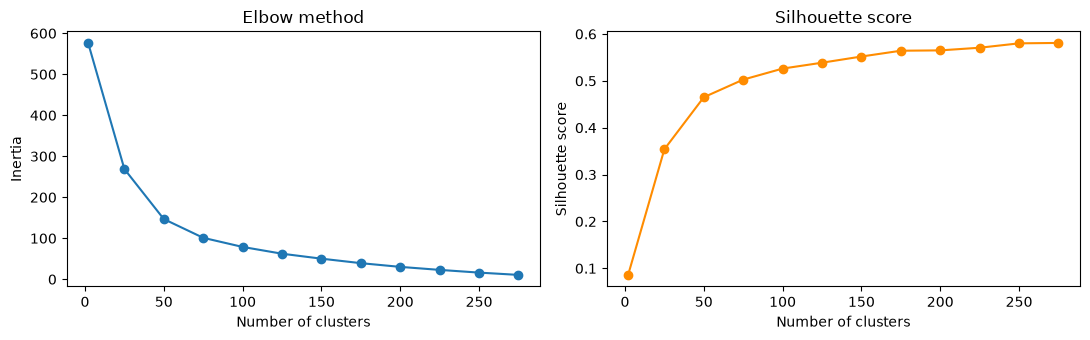

{2: np.float64(0.086), 25: np.float64(0.354), 50: np.float64(0.465), 75: np.float64(0.503), 100: np.float64(0.526), 125: np.float64(0.539), 150: np.float64(0.552), 175: np.float64(0.564), 200: np.float64(0.565), 225: np.float64(0.571), 250: np.float64(0.58), 275: np.float64(0.581)}


In [38]:
# Map the inertia (elbow method) and the silhouette score for different numbers of clusters
from sklearn.metrics import silhouette_score

ks = [2] + list(range(25, 300, 25))
inertia, silhouette = [], []
max_iter = 50
n_init = 5
random_state = 42
for k in ks:
    km = KMeans(n_clusters=k, max_iter=max_iter, n_init=n_init, random_state=random_state).fit(X_lsa)
    inertia.append(km.inertia_)  # sum of squared distances to the closest cluster center
    silhouette.append(silhouette_score(X_lsa, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ks, inertia, marker='o')
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')
axes[1].plot(ks, silhouette, marker='o', color='darkorange')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')
plt.tight_layout()
plt.show()
print(dict(zip(ks, np.round(silhouette, 3))))

The elbow in the inertia curve is gradual rather than sharp, and the silhouette score keeps creeping up as the clusters get smaller (it must - with 714 articles, tiny clusters are always tight). Both curves, however, show most of the improvement is gained by about **50 clusters** (silhouette jumps from 0.35 at 25 clusters to 0.47 at 50 but only to 0.50 at 75), while more clusters mean fewer similar articles to recommend from each cluster. We therefore use 50 clusters, about 14 articles per cluster on average.

In [39]:
n_clusters = 50  # Number of clusters
kmeans = KMeans(
    n_clusters=n_clusters,
    max_iter=max_iter,
    n_init=n_init,
    random_state=random_state,
).fit(X_lsa)

In [40]:
# create a new column `title_cluster` and assign it the kmeans cluster labels
# First we need to map the labels to df_unique_articles article ids and then apply those to df
article_cluster_map = dict(zip(df_unique_articles['article_id'], kmeans.labels_))  # Map article_id to cluster label
df['title_cluster'] = df['article_id'].map(article_cluster_map)

In [41]:
# Let's check the number of articles in each cluster
np.array(np.unique(kmeans.labels_, return_counts=True)).T

array([[ 0, 11],
       [ 1, 37],
       [ 2, 23],
       [ 3, 71],
       [ 4, 20],
       [ 5, 28],
       [ 6, 32],
       [ 7, 19],
       [ 8, 41],
       [ 9, 13],
       [10, 29],
       [11,  6],
       [12, 20],
       [13, 12],
       [14,  7],
       [15, 14],
       [16, 22],
       [17,  4],
       [18,  7],
       [19, 10],
       [20, 10],
       [21,  9],
       [22,  7],
       [23,  9],
       [24,  7],
       [25,  8],
       [26,  9],
       [27, 11],
       [28,  7],
       [29,  5],
       [30, 16],
       [31, 12],
       [32, 12],
       [33,  9],
       [34, 13],
       [35, 10],
       [36, 18],
       [37, 15],
       [38,  8],
       [39,  7],
       [40,  6],
       [41, 18],
       [42,  8],
       [43,  7],
       [44,  5],
       [45,  9],
       [46,  8],
       [47,  7],
       [48,  8],
       [49, 10]])

In [42]:
def get_similar_articles(article_id, df=df):
    """
    INPUT:
    article_id - (int) an article id
    df - (pandas dataframe) df as defined at the top of the notebook

    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster

    Description:
    Returns a list of the article ids that are in the same title cluster
    """
    title_cluster = df.loc[df['article_id'] == article_id, 'title_cluster'].iloc[0]
    articles_in_cluster = df.loc[df['title_cluster'] == title_cluster, 'article_id'].unique().tolist()

    # remove the input article_id from the list
    articles_in_cluster.remove(article_id)

    return articles_in_cluster

In [43]:
def make_content_recs(article_id, n, df=df):
    """
    INPUT:
    article_id - (int) an article id
    n - (int) the number of recommendations you want similar to the article id
    df - (pandas dataframe) df as defined at the top of the notebook

    OUTPUT:
    n_ranked_similar_articles - (list) a list of article ids that are in the same title cluster ranked
                                by popularity
    n_ranked_article_names - (list) a list of article names associated with the list of article ids

    Description:
    Returns a list of the n most ranked similar articles to a given article_id based on the title
    cluster in df. Rank similar articles using the function get_ranked_article_unique_counts.
    """
    similar = get_similar_articles(article_id, df)
    ranked = get_ranked_article_unique_counts(similar)[:n]
    n_ranked_similar_articles = [a for a, _ in ranked]
    return n_ranked_similar_articles, get_article_names(n_ranked_similar_articles, df)

In [44]:
# Test out your content recommendations given artice_id 25
rec_article_ids, rec_article_titles = make_content_recs(25, 10)
print(rec_article_ids)
print(rec_article_titles)

[1025, 101, 975, 766, 508, 547, 132, 878, 92, 693]
['data tidying in data science experience', 'how to choose a project to practice data science', 'the data science process', 'making data science a team sport', 'data science in the cloud', 'trust in data science', 'collecting data science cheat sheets', '10 data science podcasts you need to be listening to right now', '9 mistakes to avoid when starting your career in data science', 'better together: spss and data science experience']


In [45]:
assert len({1025, 593, 349, 821, 464, 29, 1042, 693, 524, 352}.intersection(set(rec_article_ids))) > 0, "Oops! Your the make_content_recs function doesn't work quite how we expect."

`2.` Now that you have put together your content-based recommendation system, use the cell below to write a summary explaining how your content based recommender works.  Do you see any possible improvements that could be made to your function? What other text data would be useful to help make better recommendations besides the article title?

**How the content-based recommender works.** Each article title is turned into a TF-IDF vector (English stop words removed; words in fewer than 5 titles or more than 75% of titles ignored, leaving 125 vocabulary terms). Because TF-IDF vectors are sparse and high-dimensional, they are compressed with truncated SVD (LSA) to 50 dimensions and length-normalised, so that titles using *related* words (not just identical words) end up close together. KMeans then groups the 714 articles into 50 clusters. `make_content_recs(article_id, n)` finds the cluster of the given article and returns the `n` other articles in that cluster, ranked by how many unique users have read them. For article 25 it returns data-science-themed articles ("the data science process", "data science in the cloud", ...), which is sensible.

**Strengths:** needs no user history, so it works for new articles and new users who have clicked just one article; recommendations are explainable ("same topic").

**Limitations and improvements:**
* Titles are short; clusters are hard (an article either is in a cluster or is not) and clusters can be uneven in size (from 4 to 71 articles). Ranking by cosine similarity to the article inside the LSA space - instead of cluster membership - would give a finer-grained, always-length-`n` result.
* Better text would help most: the article **body, abstract, tags/categories, author and publication date**. With richer text we could use document embeddings (e.g. sentence-transformers) instead of TF-IDF.
* Popularity ranking inside the cluster favours old articles; adding **recency** and the user's own history (e.g. blend with the SVD similarity) would make the list more personal.

### <a class="anchor" id="Matrix-Fact">Part V: Matrix Factorization</a>

In this part of the notebook, you will build use matrix factorization to make article recommendations to users.

`1.` You should have already created a **user_item** matrix above in **question 1** of **Part III** above.  This first question here will just require that you run the cells to get things set up for the rest of **Part V** of the notebook. 

In [46]:
# quick look at the matrix
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


`2.` In this situation, you can use Singular Value Decomposition from [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) on the user-item matrix.  Use the cell to perform SVD.

**Why SVD works here.** The user-item matrix $R$ ($5149 \times 714$) is binary, with no missing values: a 0 means "has not interacted (yet)", not "unknown". Traditional SVD, which is undefined for matrices with missing entries (as in the Netflix-style ratings problem where FunkSVD is required), can therefore be applied directly. SVD factorises $R = U \Sigma V^T$ where $U$ ($5149 \times k$) describes how strongly each user loads on each latent feature, $V^T$ ($k \times 714$) describes how each article loads on those features, and the singular values in $\Sigma$ order the latent features by how much of the interaction pattern they explain. Keeping only the top $k$ features gives the best rank-$k$ approximation of $R$ and forces the model to capture shared structure (groups of users reading similar topics) rather than memorise individual interactions. Articles with similar columns in $V^T$ are read by similar kinds of users, which is what the item-item recommender at the end uses.

*Implementation note:* scikit-learn's `TruncatedSVD.fit_transform` returns $U\Sigma$ rather than $U$; the cell below recovers $U$ by dividing by the singular values and verifies that $U \Sigma V^T$ reproduces the matrix.

In [47]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import precision_score, recall_score, accuracy_score
# Using the full number of components which equals the number of columns
svd = TruncatedSVD(n_components=len(user_item.columns), n_iter=5, random_state=42)

u = svd.fit_transform(user_item)  # NOTE: sklearn returns U @ diag(Sigma) here, not U itself
v = svd.components_  # V transpose
s = svd.singular_values_
print('u', u.shape)
print('s', s.shape)
print('vt', v.shape)

# Recover the orthonormal U (u / s). The last ~10 singular values are numerically zero (the matrix has rank < 714), so only
# the components with a non-negligible singular value are used for the check.
keep = s > 1e-6
U, sigma, vt = u[:, keep] / s[keep], s[keep], v[keep]
print('U', U.shape, 'Sigma', sigma.shape, 'Vt', vt.shape)
print('U columns orthonormal:', np.allclose(U.T @ U, np.eye(U.shape[1]), atol=1e-4))
print('max reconstruction error of U @ diag(Sigma) @ Vt:', np.abs(U @ np.diag(sigma) @ vt - user_item.values).max())

u (5149, 714)
s (714,)
vt (714, 714)
U (5149, 704) Sigma (704,) Vt (704, 714)
U columns orthonormal: True


max reconstruction error of U @ diag(Sigma) @ Vt: 6.106226635438361e-15


`3.` Now for the tricky part, how do we choose the number of latent features to use?  Running the below cell, you can see that as the number of latent features increases, we obtain better metrics when making predictions for the 1 and 0 values in the user-item matrix.  Run the cell below to get an idea of how our metrics improve as we increase the number of latent features.

Text(0.5, 1.0, 'Metrics vs. Number of Latent Features')

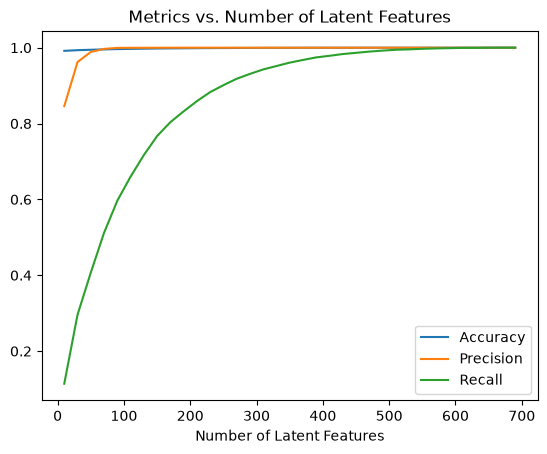

In [48]:
num_latent_feats = np.arange(10, 700+10, 20)
metric_scores = []

for k in num_latent_feats:
    # restructure with k latent features
    u_new, vt_new = u[:, :k], v[:k, :]
    
    # take dot product
    user_item_est = abs(np.around(np.dot(u_new, vt_new))).astype(int)
    # make sure the values are between 0 and 1
    user_item_est = np.clip(user_item_est, 0, 1)
    
    # total errors and keep track of them
    acc = accuracy_score(user_item.values.flatten(), user_item_est.flatten())
    precision = precision_score(user_item.values.flatten(), user_item_est.flatten())
    recall = recall_score(user_item.values.flatten(), user_item_est.flatten())
    metric_scores.append([acc, precision, recall])
    
    
plt.plot(num_latent_feats, metric_scores, label=['Accuracy', 'Precision', 'Recall'])
plt.legend()
plt.xlabel('Number of Latent Features')
plt.title('Metrics vs. Number of Latent Features')

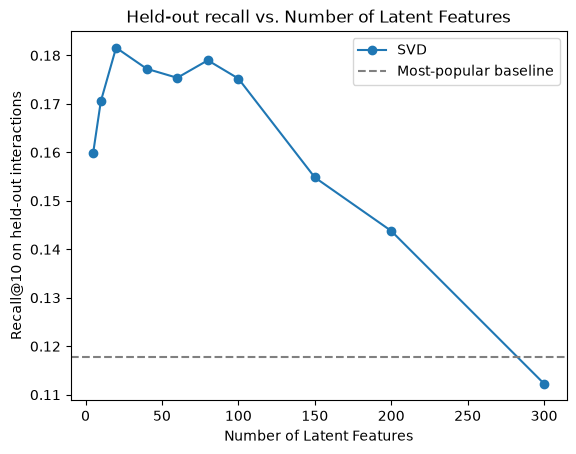

{5: np.float64(0.1599), 10: np.float64(0.1705), 20: np.float64(0.1816), 40: np.float64(0.1772), 60: np.float64(0.1754), 80: np.float64(0.179), 100: np.float64(0.1752), 150: np.float64(0.1548), 200: np.float64(0.1438), 300: np.float64(0.1123)} baseline: 0.1178


In [49]:
# In-sample accuracy always improves with k, so also measure *generalisation*:
# hide 20% of each user's interactions, factorise the remaining matrix, and check how many of the
# hidden articles appear in the user's top-10 predicted (unseen) articles, vs. a popularity baseline.
rng = np.random.default_rng(42)
R = user_item.values.copy()
train, hidden = R.copy(), np.zeros_like(R)
for i in range(R.shape[0]):
    items = np.flatnonzero(R[i])
    if len(items) >= 5:  # only users with enough history are evaluated
        held_items = rng.choice(items, size=max(1, int(0.2 * len(items))), replace=False)
        train[i, held_items] = 0
        hidden[i, held_items] = 1
eval_users = hidden.sum(axis=1) > 0

svd_cv = TruncatedSVD(n_components=300, n_iter=5, random_state=42)
u_cv = svd_cv.fit_transform(train)
vt_cv = svd_cv.components_


def recall_at_n(scores, n=10):
    """Share of hidden articles found in each evaluated user's top-n unseen articles (averaged over users)."""
    scores = np.where(train == 1, -np.inf, scores)  # never recommend what the user already has in train
    top = np.argsort(-scores, axis=1)[:, :n]
    hits = np.take_along_axis(hidden, top, axis=1).sum(axis=1)
    return (hits[eval_users] / hidden.sum(axis=1)[eval_users]).mean()


ks_cv = [5, 10, 20, 40, 60, 80, 100, 150, 200, 300]
recall_cv = [recall_at_n(u_cv[:, :k] @ vt_cv[:k, :]) for k in ks_cv]
popularity_baseline = recall_at_n(np.tile(train.sum(axis=0), (R.shape[0], 1)).astype(float))

plt.plot(ks_cv, recall_cv, marker='o', label='SVD')
plt.axhline(popularity_baseline, color='gray', linestyle='--', label='Most-popular baseline')
plt.xlabel('Number of Latent Features')
plt.ylabel('Recall@10 on held-out interactions')
plt.title('Held-out recall vs. Number of Latent Features')
plt.legend()
plt.show()
print(dict(zip(ks_cv, np.round(recall_cv, 4))), 'baseline:', round(popularity_baseline, 4))

`4.` From the above, we can't really be sure how many features to use, because simply having a better way to predict the 1's and 0's of the matrix doesn't exactly give us an indication of if we are able to make good recommendations. Given the plot above, what would you pick for the number of latent features and why?

**Choice: about 20-40 latent features (the held-out curve peaks at 20, and 40 is within noise of it), certainly not 200+.**

The first plot (accuracy / precision / recall on the *same* matrix the SVD was fitted on) improves monotonically with more latent features and is misleading for choosing $k$:
* the matrix is 99.1% zeros, so accuracy is already 99.2% with only 10 features and carries almost no information;
* precision is ~1.0 almost immediately, and recall just keeps rising (0.41 at 50 features, 0.85 at 200, 1.0 at 700) because with more latent features the model simply **memorises** the training interactions - at 714 features it reconstructs the matrix exactly. That is overfitting: a model that reproduces known 1's perfectly says nothing about *new* articles a user would like.

The second plot measures what we actually care about: after hiding 20% of each user's interactions, how many of the hidden articles show up in the top-10 recommendations (recall@10). It peaks at **20 latent features (0.18)**, stays near it until roughly 100, then decays as the model starts to fit noise; by 300 features it falls to 0.11 - *below* the simple most-popular baseline (0.12). So the optimal number of latent features is small (about 20-40); more features only help reproduce the training data.

(The item-item similarity below uses 200 features as the task specifies; with that many features similarities between rarely-read articles are noisy, so a smaller $k$ is advisable in production.)

`5.` Using 200 latent features and the values of U, S, and V transpose we calculated above, create an article id recommendation function that finds similar article ids to the one provide.

Create a list of 10 recommendations that are similar to article with id 4.  The function should provide these recommendations by finding articles that have the most similar latent features as the provided article.

In [50]:
def get_svd_similar_article_ids(article_id, vt, user_item=user_item, include_similarity=False):
    """
    INPUT:
    article_id - (int) an article id
    vt - (numpy array) vt matrix from SVD
    user_item - (pandas dataframe) matrix of users by articles:
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output

    OUTPUT:
    article_ids - (list) a list of article ids ordered from most to least similar in latent space

    Description:
    Returns a list of the article ids similar using SVD factorization
    """
    # Find the index of the article_id
    article_idx = user_item.columns.get_loc(article_id)
    # Find the cosine similarity of all articles (each article is a column of vt, i.e. a row of vt.T)
    cos_sim = cosine_similarity(vt.T)
    # Get similarities only for the cos_sim of the article_idx
    sims = cos_sim[article_idx]

    # Sort and return the articles, don't include the own article
    order = np.argsort(-sims, kind='stable')
    order = order[order != article_idx]
    most_similar_items = user_item.columns[order].tolist()

    if include_similarity:
        return [[a, s] for a, s in zip(most_similar_items, sims[order])]
    return most_similar_items

In [51]:
# Create a vt_new matrix with 200 latent features
k = 200
vt_new = v[:k, :]

In [52]:
# What is the article name for article_id 4?
print("Current article:", get_article_names([4], df=df)[0])

Current article: analyze ny restaurant data using spark in dsx


In [53]:
# What are the top 10 most similar articles to article_id 4?
rec_articles = get_svd_similar_article_ids(4, vt_new, user_item=user_item)[:10]
rec_articles

[1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132]

In [54]:
# What are the top 10 most similar articles to article_id 4?
get_article_names(rec_articles, df=df)

['country statistics: crude oil - exports',
 'airbnb data for analytics: athens reviews',
 'use spark r to load and analyze data',
 'country statistics: crude oil - proved reserves',
 'top analytics tools in 2016',
 'airbnb data for analytics: paris calendar',
 'notebooks: a power tool for data scientists',
 '10 powerful features on watson data platform, no coding necessary',
 'advancements in the spark community',
 'collecting data science cheat sheets']

In [55]:
assert set(rec_articles) == {1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132}, "Oops! Your the get_svd_similar_article_ids function doesn't work quite how we expect."
print("That's right!  Great job!")

That's right!  Great job!


`6.` Use the cell below to comment on the results you found in the previous question. Given the circumstances of your results, discuss what you might do to determine if the recommendations you make above are an improvement to how users currently find articles, either by Sections 2, 3, or 4? Add any tradeoffs between each of the methods, and how you could leverage each type for different situations including new users with no history, recently new users with little history, and users with a lot of history. 

**Results.** For article 4 ("analyze ny restaurant data using spark in dsx") the SVD item-item recommender returns other data-analysis/Spark articles (e.g. "use spark r to load and analyze data", "notebooks: a power tool for data scientists") mixed with some generic data-set articles (country statistics, airbnb data). The recommendations are topically plausible, but they come purely from co-reading behaviour, so they also include articles that are popular with the same audience rather than the same topic, and with 200 latent features similarity for rarely-read articles is noisy.

**Trade-offs of the methods**

| Method | Needs | Strengths | Weaknesses |
|---|---|---|---|
| Rank-based | nothing | simple, robust, works for anyone | not personal; popular items get more popular |
| User-user CF | user history | personalised, serendipitous | cold start; slow to scale (similarity to every user); sparse data (median user has 3 interactions) |
| Content-based (TF-IDF + KMeans) | article text | works for new articles and after a single click; explainable | titles are short; limited to "same topic"; no personalisation |
| SVD (matrix factorisation) | interaction matrix | captures latent tastes; compact; fast at serving time | cold start for users and articles; binary data with no negatives; must be re-fitted |

**Which to use when:** *brand-new users* - rank-based (optionally filtered by topics chosen at sign-up); *recently new users* (1-5 interactions) - content-based and SVD item-item recommendations from the articles they already read, blended with popularity; *users with a lot of history* - user-user CF / SVD, with content-based recommendations as a fallback for new articles.

**How to test whether the recommendations are better.** Offline we can hide part of each user's interactions and measure recall@k/precision@k/NDCG against the baseline (as done above for the SVD, where the model beats the popularity baseline for small and moderate $k$ but not for 300 features). Offline numbers cannot tell us whether users actually engage more, so we would run an **online A/B test**: randomly split users into a control group, who see the current way of finding articles (e.g. newest/popular), and one or more treatment groups, who see each recommender on their dashboard. For each group we measure click-through rate on recommended articles, articles read per user per week, return rate and time-to-first-interaction (separately for new, recent and heavy users), run until the result is statistically significant (e.g. a two-proportion z-test on CTR), and also watch diversity/coverage so that we do not only recommend the same few popular articles.

<a id='conclusions'></a>
### Extras
The recommenders in this notebook are packaged as a reusable class, `IBMRecommender`, in the [`ibm_recommender`](../ibm_recommender) package (pip-installable), and a small Flask app ([`webapp/app.py`](../webapp/app.py)) exposes them as a JSON API. See the repository README for usage.

## Conclusion

We explored the interaction data (5,149 users, 714 articles, 45,993 interactions; a heavily skewed distribution with a median of 3 articles per user) and built four recommenders, each suited to a different situation: popularity for new users, user-user collaborative filtering for users with history, TF-IDF/KMeans content recommendations for "similar articles", and SVD matrix factorisation. Evaluating on held-out interactions showed that more latent features means better reconstruction but worse recommendations, and an online A/B test is the next step to find out which approach really increases engagement.

In [56]:
# Export an HTML copy of this notebook for submission
from subprocess import call
call(['python', '-m', 'jupyter', 'nbconvert', '--to', 'html', 'Recommendations_with_IBM.ipynb'])

0